|字段|含义|类型|
|:--:|:--:|:--:|
|age |年龄|连续|
|marital |婚姻状态估计|连续|
|risk_score |个人风险偏好评分|连续|
|auto_member |是否参加车友会|连续|
|computer_owner |是否有电脑|二分类|
|HH_adults_num |家庭成年人数量|连续|
|HH_dieting |注重饮食|连续|
|HH_grandparent|是否有祖父母|连续|
|HH_has_children |是否有孩子|二分类|
|HH_head_age|家长年龄|连续|
|home_value |房屋价值|连续|
|interested_gambling |博彩兴趣|二分类|
|interested_golf |高尔夫兴趣|二分类|
|interested_reading |阅读兴趣|有序分类|
|interested_sport |运动兴趣|连续|
|interested_travel |旅游兴趣|二分类|
|loan_ratio|借贷杠杆|连续|

1、数据集中的变量较多，如果全部进入模型会导致模型解释困难。因此，一方面我们对于有相关性的变量进行降维，减少变量数目；另一方面，基于业务理解，我们预先将变量进行分组，使得同一组的变量能尽量解释业务的一个方面。比如本例中将变量分成两组，分别是家庭基本情况和用户爱好，通过对每组变量分别进行聚类，获取用户的侧写，再将两个聚类结果进行综合，以获得较完整的用户画像。

2、本例中数据类型复杂，包含了连续变量、无序分类和有序分类变量。由于K-means仅用于连续型变量聚类，因此需要对变量进行预处理。对于有序分类变量，如果分类水平较多可以视作连续变量处理，否则视作无序分类变量一样处理，再进入模型；无序分类变量数目较少时，可以使用其哑变量编码进入模型。本例中由于有较多的二分类变量，又集中在用户爱好这一方面，因此我们将interested_reading这一有序分类变量二值化，再与其他几个二分类变量一起进行汇总，得到用户的“爱好广度”，使用“爱好广度”与其他连续型的爱好类变量进行聚类。

3、离散变量如HH_has_children一般不参与聚类，因为其本身就可以视作是簇的标签；如果为了后期解释模型时简化处理，在离散变量不多的情况之下，也可以做哑变量变换后进入模型。

## 读取数据

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns",7)  # 为方便截图设置最大显示列数为7

customer = pd.read_csv('data_clust.csv',skipinitialspace=True)
customer.describe(include='all')

,age,marital,risk_score,...,interested_sport,interested_travel,loan_ratio
count,167177.000000,167177.000000,167177.000000,...,167177.000000,149788.000000,167177.000000
unique,NaN,NaN,NaN,...,NaN,NaN,NaN
top,NaN,NaN,NaN,...,NaN,NaN,NaN
freq,NaN,NaN,NaN,...,NaN,NaN,NaN
mean,59.507079,6.884015,817.031751,...,259.431776,0.427745,66.762707
std,14.311733,2.610552,165.490295,...,78.867456,0.494753,9.751835
min,18.000000,1.000000,1.000000,...,60.000000,0.000000,0.000000
25%,49.000000,5.000000,748.000000,...,204.000000,0.000000,63.000000
50%,59.000000,7.000000,844.000000,...,251.000000,0.000000,69.000000
75%,70.000000,9.000000,945.000000,...,306.000000,1.000000,73.000000


In [2]:
customer.head()

,age,marital,risk_score,...,interested_sport,interested_travel,loan_ratio
0,64,3,932,...,312,NaN,73
1,69,7,1000,...,241,0.0,73
2,57,1,688,...,367,0.0,77
3,80,7,932,...,291,1.0,74
4,48,10,987,...,137,1.0,77


## 数据预处理

#### 填补缺失值

有缺失情况的变量皆为分类变量，且缺失比例并不高，因此用众数进行填补

In [3]:
for col in customer.columns:
    if customer[col].hasnans:
        print(col)

computer_owner
HH_adults_num
HH_has_children
interested_travel


In [4]:
fill_cols = ['interested_travel', 'computer_owner', 'HH_adults_num']
fill_values = {col: customer[col].mode()[0] for col in fill_cols}

customer = customer.fillna(fill_values)

#### 修正错误值

HH_has_children的分类水平以字符形式表示，需要转换为整型，同时其中的缺失值应当表示没有小孩，因此替换为0
阅读爱好interested_reading中包含错误值“.”，将其以0进行替换，代表该用户对阅读没有兴趣。

In [5]:
customer['interested_reading'].value_counts(dropna=False)

3    65096
1    43832
0    32919
2    24488
.      842
Name: interested_reading, dtype: int64

In [6]:
customer['HH_has_children'] = customer['HH_has_children']\
    .replace({'N':0, 'Y':1, np.NaN:0})
    
customer['interested_reading'] = customer['interested_reading']\
    .replace({'.':'0'}).astype('int')

#### 对离散型变量进行处理

- 使用k-means聚类，一般不分析离散变量，但可以根据业务理解，将离散型变量进行变换

分析离散变量的相关性

In [7]:
from itertools import combinations
from scipy import stats

_cols = [
    'interested_travel',
    'computer_owner',
    'marital',
    'interested_golf', 
    'interested_gambling', 
    'HH_has_children',
    'interested_reading'
]

sample = customer[_cols].sample(3000, random_state=12345)

for colA, colB in combinations(_cols, 2):
    crosstab = pd.crosstab(sample[colA], sample[colB])
    pval = stats.chi2_contingency(crosstab)[1]
    if pval > 0.05:
        print('p-value = %0.3f between "%s" and "%s"' %(pval, colA, colB))

p-value = 0.710 between "interested_travel" and "HH_has_children"
p-value = 0.495 between "computer_owner" and "HH_has_children"
p-value = 0.272 between "interested_golf" and "HH_has_children"


对于用户爱好，可以将旅行、电脑、高尔夫、博彩、阅读这几个分类型变量综合成一个爱好广度指标，其代表了用户休闲娱乐爱好，而连续型的interested_sport、HH_dieting属于健康类爱好，auto_member属于奢侈型爱好，因此，可以从多个角度来分析用户的爱好。

- 先对interested_reading进行二值化

In [8]:
from sklearn.preprocessing import Binarizer

# 二值化
binarizer = Binarizer(threshold=1.5)
customer['interested_reading'] = binarizer.fit_transform(
    customer[['interested_reading']])

- 生成二分类偏好填充率

In [9]:
# 生成偏好填充率
interest =[
    'interested_travel',
    'computer_owner',
    'interested_golf', 
    'interested_gambling',
    'interested_reading'
]
n_ = len(interest)

customer = customer.drop(interest, axis=1)\
               .assign(interest=customer[interest].sum(axis=1) / n_)

customer.head()

,age,marital,risk_score,...,interested_sport,loan_ratio,interest
0,64,3,932,...,312,73,0.2
1,69,7,1000,...,241,73,0.4
2,57,1,688,...,367,77,0.2
3,80,7,932,...,291,74,1.0
4,48,10,987,...,137,77,0.8


#### 正态化、标准化

- 对不同类型变量执行不同处理，连续变量、有序分类变量及无序分类变量在处理上均有不同，因此先按类型对变量分组，不同组采用不同的处理策略
- 如果一个连续变量的可能取值很少，如marital（10个水平）、interest（5个水平）、HH_adults_num（8个水平）等，当将其作为普通连续变量一样进行分布转换，可能生成一些离群值（例如对marital使用scikit-learn进行正态转换，会发现1和10对应的数据点离开均值达到5个标准差）。因此本例中将这几个连续变量作为有序分类变量对待，但不进行分布转化，仅做标准化处理。

In [10]:
# 所有变量划分为连续、有序分类和离散，以便后续处理
continuous_cols = ['age', 'home_value', 'risk_score', 'interested_sport', 
                   'HH_dieting', 'auto_member', 'HH_grandparent',
                   'HH_head_age', 'loan_ratio']

categorical_cols = ['marital', 'interest', 'HH_adults_num']

discreate_cols = ['HH_has_children']

为了聚类后的簇大小能比较接近，对于偏态严重的连续变量应转换其分布，令其接近正态分布或均匀分布

- 对连续变量正态化

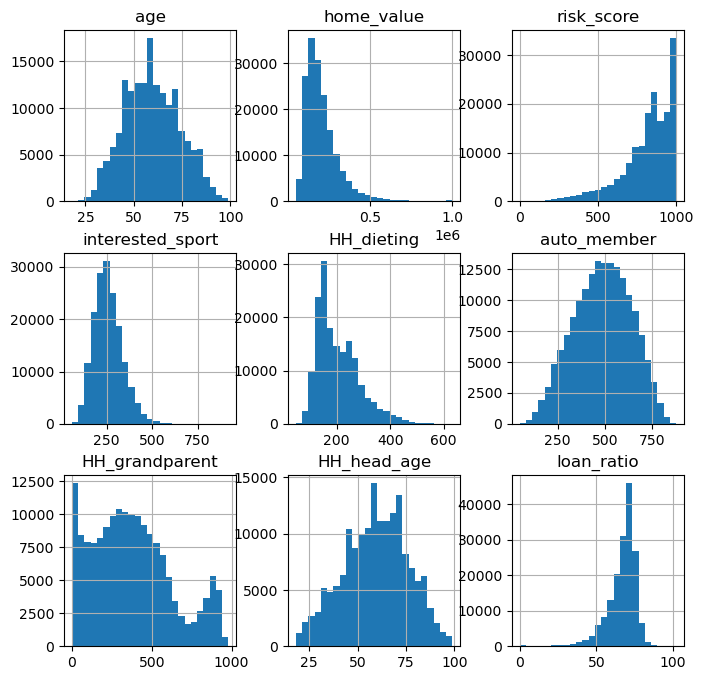

In [11]:
customer[continuous_cols].hist(bins=25, figsize=[8, 8])
plt.show()

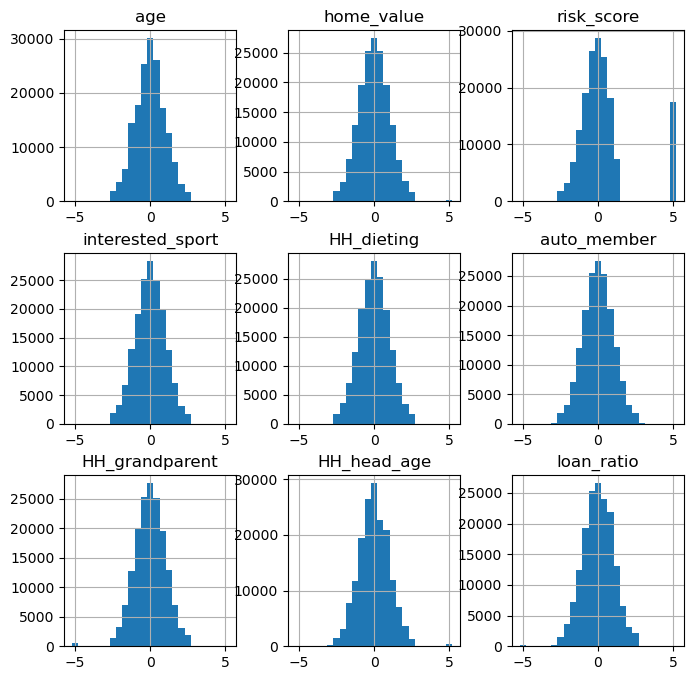

In [17]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(n_quantiles=100, output_distribution='normal')
qt_data = qt.fit_transform(customer[continuous_cols])

pd.DataFrame(qt_data, columns=continuous_cols).hist(bins=25, figsize=[8, 8])
plt.show()

- 对有多个水平的有序分类变量进行标准化

如前所述，尽管HH_adults_num、marital和interest属于连续变量，但都仅有不到10个水平，因此与有序分类变量一样，仅做标准化

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scale_data = scaler.fit_transform(customer[categorical_cols])

对二分类变量不做处理，合并各类型的变量

In [19]:
data = np.hstack([qt_data, scale_data, customer[discreate_cols]])
data = pd.DataFrame(
    data, columns=continuous_cols + categorical_cols + discreate_cols)

In [20]:
data.head()

,age,home_value,risk_score,...,interest,HH_adults_num,HH_has_children
0,0.321971,-0.895167,0.574460,...,-1.035281,-0.547836,0.0
1,0.619855,-0.626444,5.199338,...,-0.354828,1.895118,0.0
2,-0.126937,-0.467533,-0.929919,...,-1.035281,-0.547836,0.0
3,1.335178,-0.255097,0.574460,...,1.686529,-0.547836,1.0
4,-0.747859,-0.713318,1.144237,...,1.006077,0.266482,1.0


### 维度分析

#### 根据业务需求，将变量从两个大的维度进行考虑
- 其一为用户家庭属性（包括家庭基本情况及财务情况），其二为用户个人偏好情况（包括对运动、节食等的兴趣程度）

In [21]:
household = ['age', 'marital', 'HH_adults_num', 'home_value', 
             'risk_score', 'HH_grandparent', 'HH_head_age', 'loan_ratio']
hobby = ['HH_dieting', 'auto_member','interest', 'interested_sport']
#  'HH_has_children' 暂不进入模型 

In [22]:
data[hobby].corr()

,HH_dieting,auto_member,interest,interested_sport
HH_dieting,1.000000,0.134364,0.246782,0.510858
auto_member,0.134364,1.000000,0.316900,0.458820
interest,0.246782,0.316900,1.000000,0.219860
interested_sport,0.510858,0.458820,0.219860,1.000000


In [23]:
data[household].to_numpy()

array([[ 0.32197089, -1.48781841, -0.54783575, ...,  0.2592342 ,
         2.50859572,  0.69852571],
       [ 0.61985457,  0.04442938,  1.89511842, ...,  1.18224646,
         0.45867907,  0.69852571],
       [-0.12693746, -2.25394231, -0.54783575, ..., -0.44665711,
        -0.22988412,  1.5497059 ],
       ...,
       [-1.12020535,  0.42749133, -1.36215381, ..., -0.71886805,
        -0.98783733,  1.33517774],
       [-0.19105201,  1.19361523,  2.70943648, ..., -1.12615242,
        -0.06334102, -0.48699394],
       [-0.3894143 , -1.48781841, -0.54783575, ..., -0.02954369,
        -0.3894143 , -0.66656426]])

分别对两个维度进行因子分析，由于scikit-learn中的因子分析并不提供因子旋转，因此我们使用另外的因子分析包，例如fa-kit，这需要事先使用pip install fa-kit进行安装，参考https://github.com/bmcmenamin/fa_kit 。安装完成后，可以对用户的家庭属性和偏好属性分别进行因子分析

先使用主成分分析确定保留多少个主成分合适：

In [24]:
from sklearn.decomposition import PCA

pca_hh = PCA().fit(data[household])
pca_hh.explained_variance_ratio_.cumsum()

array([0.35339858, 0.56502732, 0.73093754, 0.83108897, 0.88468835,
       0.9291907 , 0.96736069, 1.        ])

保留4个主成分是适当的

In [25]:
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting
fa_hh = FactorAnalysis.load_data_samples(
    data[household].to_numpy(),
    preproc_demean=True,
    preproc_scale=True
)
fa_hh.extract_components()

设定提取主成分的方式。默认为“broken_stick”方法，建议使用“top_n”法

In [26]:
fa_hh.find_comps_to_retain(method='top_n',num_keep=4)

array([0, 1, 2, 3], dtype=int64)

通过最大方差法进行因子旋转

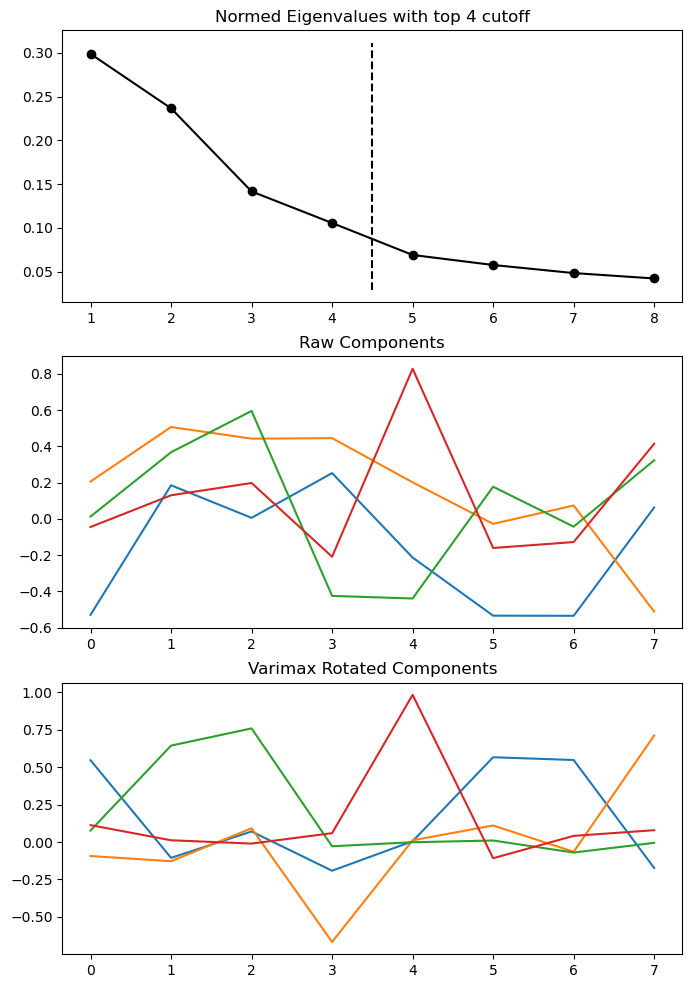

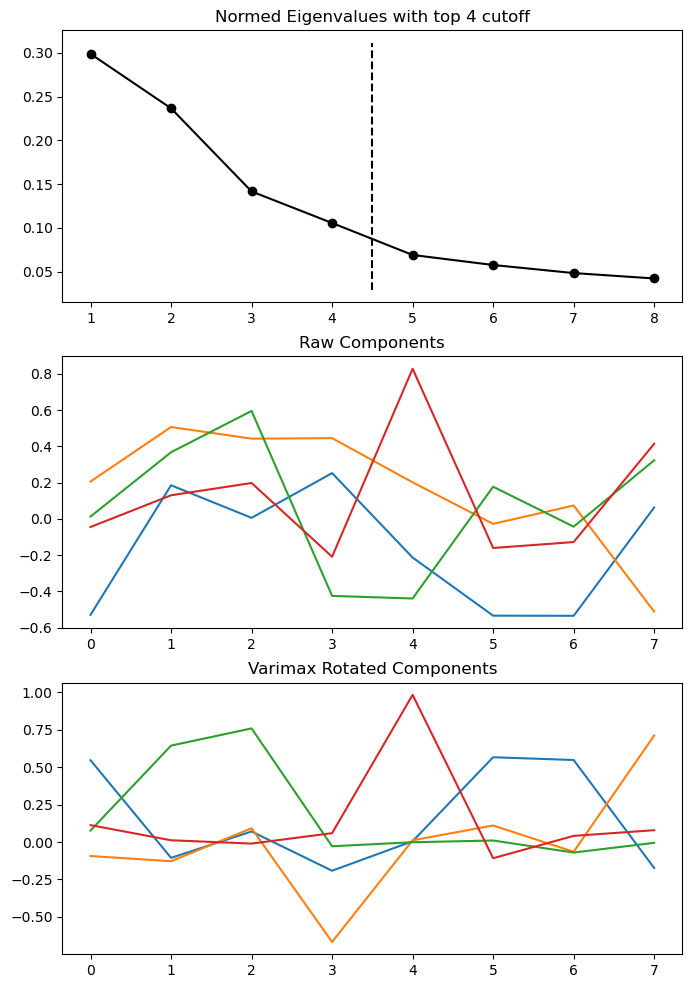

In [27]:
fa_hh.rotate_components(method='varimax')
fa_plotting.graph_summary(fa_hh)

各个因子：

In [28]:
print(pd.DataFrame(fa_hh.comps['rot'], index=household))

                       0         1         2         3
age             0.545665 -0.093711  0.076524  0.112268
marital        -0.105924 -0.128458  0.643193  0.011423
HH_adults_num   0.069995  0.091302  0.757963 -0.010727
home_value     -0.191917 -0.667140 -0.028499  0.058766
risk_score      0.004748  0.011124 -0.001774  0.981889
HH_grandparent  0.565486  0.110081  0.009768 -0.108418
HH_head_age     0.547124 -0.065472 -0.070676  0.040715
loan_ratio     -0.173656  0.710476 -0.005778  0.078610


可以看到：
- 第一个因子在age、HH_grandparent、HH_head_age上的权重显著较高，从业务上理解，这三个变量的综合可以认为是用户所处的生命周期；
- 第二个因子在home_value、loan_ratio上的权重显著较高，这个因子主要表示了用户财务状况；
- 第三个因子在marital、HH_adults_num上的权重显著较高，该因子代表了家庭的人口规模；
- 第四个因子仅在risk_score上的权重较高，因此该因子代表的就是用户的风险

计算因子得分：

In [29]:
data_hh = pd.DataFrame(
    np.dot(data[household], fa_hh.comps['rot']), 
    columns=['life_circle','finance', 'HH_size', 'risk']
)

同理，对用户的偏好属性进行因子分析（保留3个因子）：

In [30]:
fa_hb = FactorAnalysis.load_data_samples(
    data[hobby].to_numpy(), 
    preproc_demean=True,
    preproc_scale=True
)

fa_hb.extract_components()

fa_hb.find_comps_to_retain(method='top_n', num_keep=3)
fa_hb.rotate_components(method='varimax')
print(pd.DataFrame(fa_hb.comps['rot'], index=hobby))

                         0         1         2
HH_dieting       -0.175677  0.832393  0.088231
auto_member       0.868200 -0.120631  0.071107
interest          0.033364  0.027792  0.978831
interested_sport  0.462875  0.540183 -0.170440


- 第一个因子在auto_member和interested_sport上的权重较高，是对用户运动偏好的度量
- 第二个因子在HH_dieting和interested_sport上的权重较高，是对用户健康生活方式的度量
- 第三个因子仅在interest上的权重较高，是对用户休闲娱乐偏好的度量 

计算因子得分

In [31]:
data_hb = pd.DataFrame(
    np.dot(data[hobby], fa_hb.comps['rot']), 
    columns=['sports', 'health', 'leisure']
)

### 选择K-means聚类中的K值

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def cluster_plot(data, k_range=range(2, 12), n_init=5, sample_size=2000, 
                 figsize=[9, 2]):
    scores = []  #  用来保存模型效果的评分
    models = {}  #  用字典来保存模型
    
    #  遍历选择的所有k
    for k in k_range:
        kmeans = KMeans(n_clusters=k, n_init=n_init)
        kmeans.fit(data)  # 训练
        models[k] = kmeans  
        sil = silhouette_score(data, kmeans.labels_, 
                               sample_size=sample_size)  # 轮廓系数
        scores.append([k, kmeans.inertia_, sil])  # inertia_即SSD

    scores_df = pd.DataFrame(scores, columns=['k','sum_square_dist', 'sil'])
    #  绘制簇内离差平方和
    plt.figure(figsize=figsize)
    plt.subplot(121, ylabel='SSD')
    plt.plot(scores_df.k, scores_df.sum_square_dist)
    #  绘制轮廓系数
    plt.subplot(122, ylabel='silhouette_score')
    plt.plot(scores_df.k, scores_df.sil)
    plt.show()
    
    return models  # 返回不同k值对应的模型

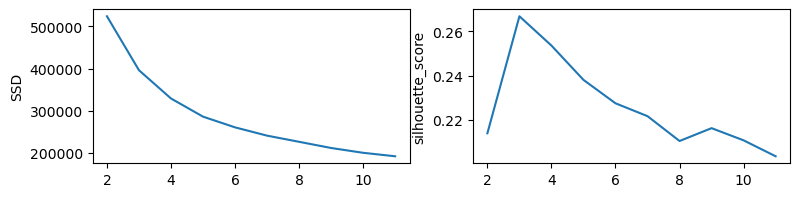

--------------------------------------------------------------------------------


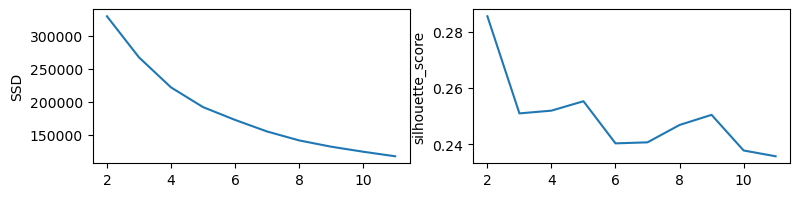

In [33]:
# 对因子得分进行标准化
hh_scaler = StandardScaler()
scale_data_hh = hh_scaler.fit_transform(data_hh)
hb_scaler = StandardScaler()
scale_data_hb = hb_scaler.fit_transform(data_hb)

# 绘制ssd、轮廓系数
models_hh = cluster_plot(scale_data_hh)
print("-" * 80)
models_hb = cluster_plot(scale_data_hb)

#### 选择适当K值分别进行聚类，并将相应标签连接至原始数据集

In [34]:
hh_labels = pd.DataFrame(models_hh[3].labels_, columns=['hh'])
hb_labels = pd.DataFrame(models_hb[2].labels_, columns=['hb'])
clusters = customer.join(hh_labels).join(hb_labels)
clusters.head()

,age,marital,risk_score,...,interest,hh,hb
0,64,3,932,...,0.2,0,1
1,69,7,1000,...,0.4,1,0
2,57,1,688,...,0.2,0,1
3,80,7,932,...,1.0,0,0
4,48,10,987,...,0.8,0,1


#### 对各个簇的特征进行描述——使用原始数据

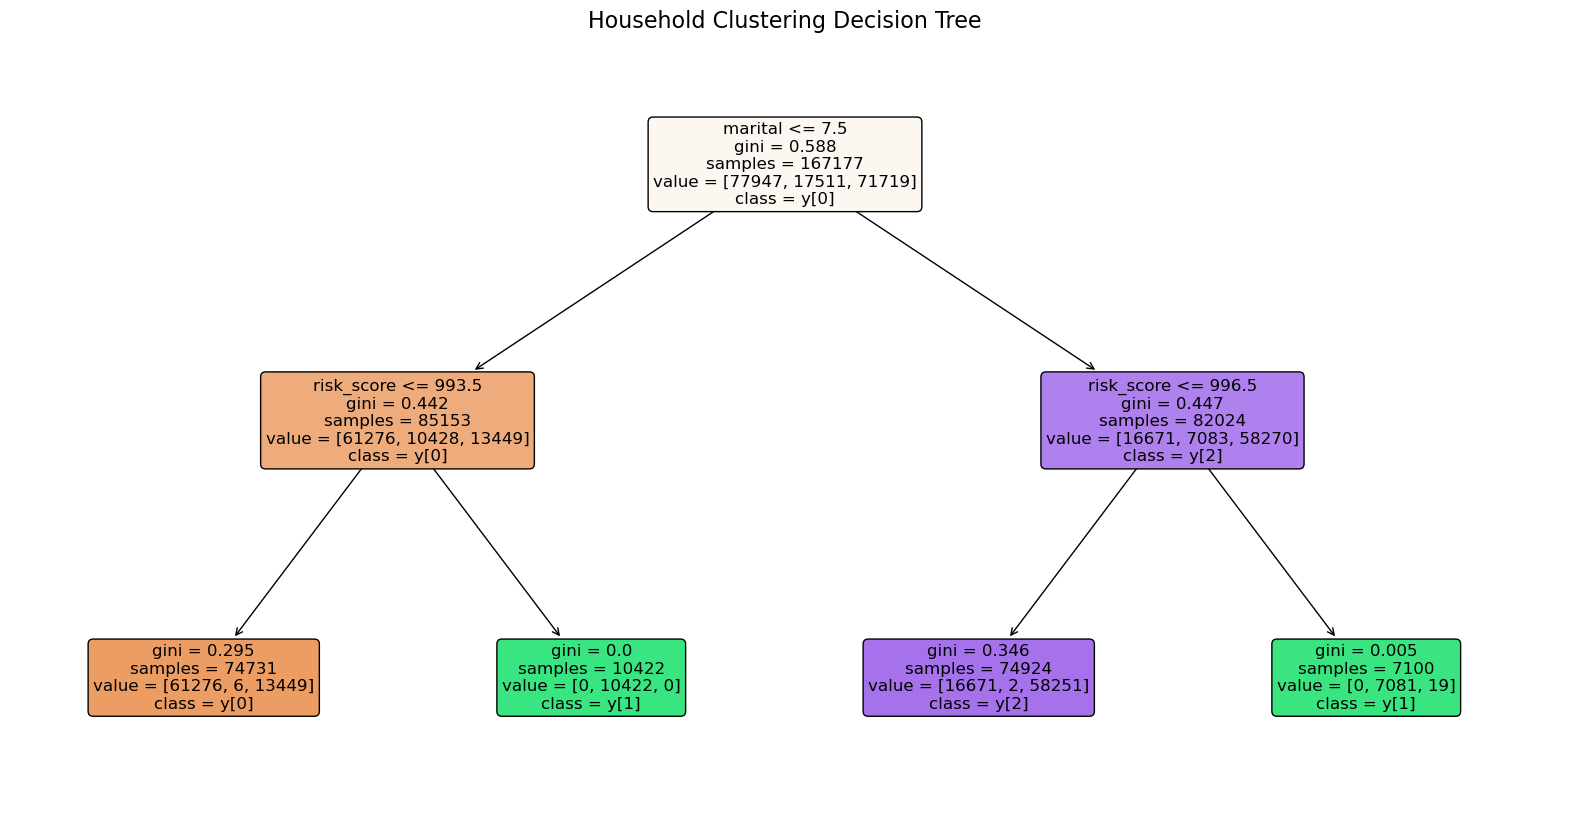

In [38]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 建立决策树
tree_hh = DecisionTreeClassifier(max_depth=2) # 可以在这里限制深度，防止树太大
tree_hb = DecisionTreeClassifier(max_depth=2)

tree_hh.fit(clusters[household], clusters['hh'])
tree_hb.fit(clusters[hobby], clusters['hb'])

# ================= 绘制 household 的决策树 =================
plt.figure(figsize=(20, 10)) # 图片可以设大一点，避免字挤在一起
plot_tree(
    tree_hh, 
    feature_names=household, 
    class_names=True, 
    filled=True, 
    rounded=True,
    fontsize=12
)
plt.title("Household Clustering Decision Tree", fontsize=16)
plt.show()

有多个属性可用于分析用户的特征，使用决策树会计算属性对于类别的重要性，因此可用于发现其中较突出的属性（特征）
- 标签hh=0用户的突出特征是已婚低风险
- 标签hh=1用户的突出特征是未婚低风险
- 标签hh=2的用户的突出特征是高风险

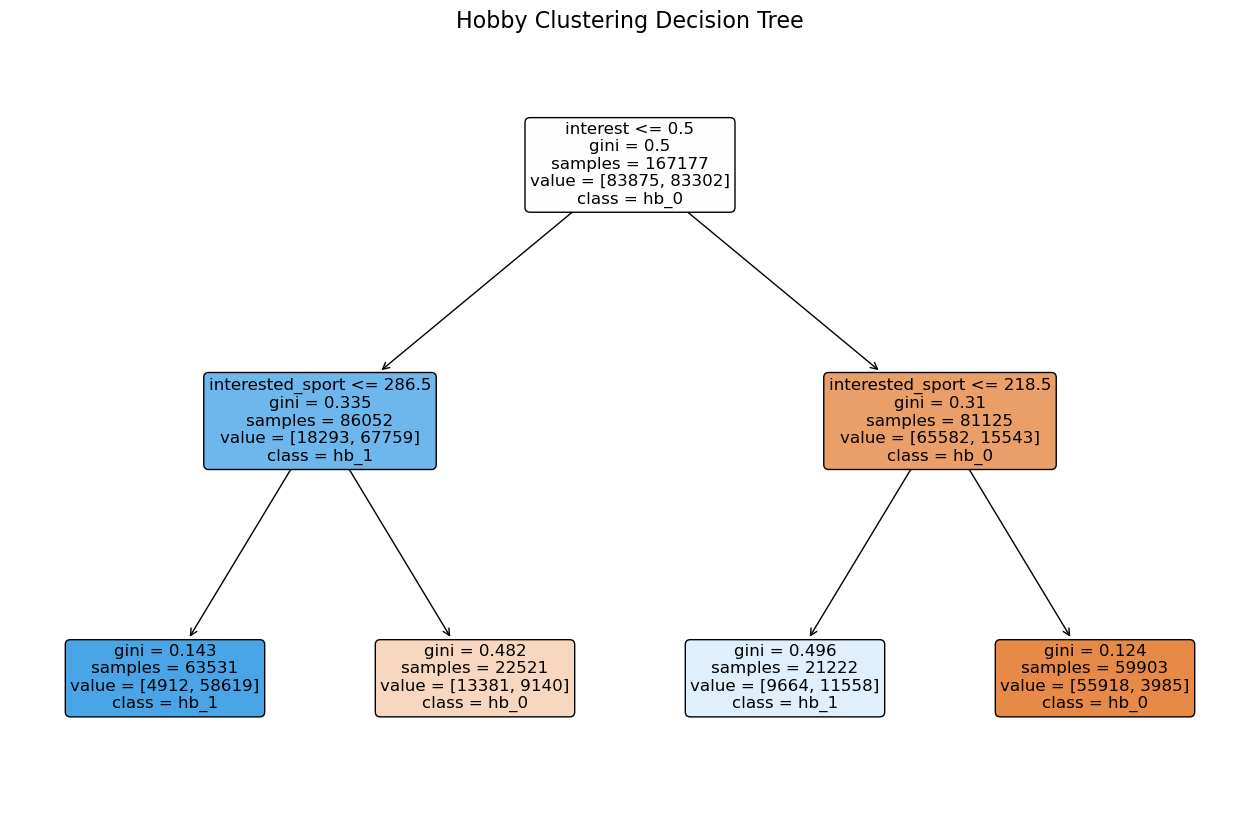

In [40]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 设置画布大小（宽, 高），数字越大图片越清晰，节点不会挤在一起
plt.figure(figsize=(16, 10)) 

# 直接绘制决策树
plot_tree(
    tree_hb,                      # 你之前训练好的模型变量名
    feature_names=hobby,          # 特征名称列表
    class_names=['hb_0', 'hb_1'], # 类别名称，代替 class_names=True，避免潜在的显示bug
    filled=True,                  # 填充颜色（根据分类结果深浅不同）
    rounded=True,                 # 节点使用圆角框
    fontsize=12                   # 字体大小
)

plt.title("Hobby Clustering Decision Tree", fontsize=16)
plt.show()

- 标签hb=0的用户的突出特征是兴趣度低、不好运动
- 标签hb=1用户的突出特征是喜欢运动及汽车俱乐部活动

#### 可以进行多维汇总分析

In [41]:
clusters

,age,marital,risk_score,...,interest,hh,hb
0,64,3,932,...,0.2,0,1
1,69,7,1000,...,0.4,1,0
2,57,1,688,...,0.2,0,1
3,80,7,932,...,1.0,0,0
4,48,10,987,...,0.8,0,1
...,...,...,...,...,...,...,...
167172,46,10,885,...,0.4,2,0
167173,51,4,874,...,0.2,0,1
167174,43,8,1000,...,0.2,1,1
167175,56,10,932,...,0.8,2,0


In [42]:
cluster_pt = pd.pivot_table(clusters, index='hh', columns='hb',
                            aggfunc='mean').T
cluster_pt.swaplevel('hb', 0).sort_index(level=0)

hh                               0              1              2
hb                                                              
0  HH_adults_num          2.196723       2.769569       3.346240
   HH_dieting           257.748281     227.821148     229.568754
   HH_grandparent       535.645343     513.927177     330.276053
   HH_has_children        0.169332       0.165837       0.371444
   HH_head_age           63.783437      67.515502      57.711114
   age                   64.289475      70.371005      60.414576
   auto_member          526.982262     596.640957     594.294509
   home_value        164409.812645  210279.233206  278336.124322
   interest               0.717806       0.690813       0.677605
   interested_sport     293.569154     319.114928     302.293495
   loan_ratio            70.413286      63.407368      60.153914
   marital                5.624363       6.862967       8.619537
   risk_score           799.609118     999.984019     845.697993
1  HH_adults_num          2.027210       2.424586       3.270317
   HH_dieting           173.643347     158.056791     166.838485
   HH_grandparent       355.913519     400.215267     268.307824
   HH_has_children        0.239012       0.148138       0.460351
   HH_head_age           57.903954      68.822263      54.525086
   age                   54.764457      66.080017      55.758884
   auto_member          366.670677     447.542841     453.719367
   home_value        155679.967798  175159.581221  237888.000000
   interest               0.297618       0.295369       0.351807
   interested_sport     208.915083     237.050843     227.254807
   loan_ratio            72.002747      68.452202      65.208654
   marital                5.205486       5.893358       8.688612
   risk_score           738.068315     999.991644     814.129091

- 重点用户群例（如果不设定kmean的randomstate 则每次执行结果可能不同，因为簇标签无顺序）:

| 客户群（簇） | 特征                                                 | 产品侧重           |
| ------------| ------------------------------------------------------------------------  | ---------------------- |
| hh=0, hb=0  | 年轻、家庭成员数少，有较高的还贷压力与较低的风险，不喜欢运动、休闲等活动  | 消费金融           |
| hh=0, hb=1  | 年轻的已婚有子中产阶层，偏爱汽车俱乐部                         | 子女保障、健康保险 |
| hh=1, hb=0  | 年轻未婚低风险高贷款率，廉价房产，无特别爱好                     | 性价比、分期付款 |
| hh=1, hb=1  | 中龄未婚，有赡养压力和还贷压力，廉价房产，爱好广                   | 养老保障、个性化 |
| hh=2, hb=0  | 高房产价值和较低贷款率的年轻已婚有子人群                        | 高端高值           |
| hh=2, hb=1  | 已婚、高房产价值、低贷款比率，家庭成员多                        | 高端理财、保险、贵金属 |